## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


The point estimate of the ATE is -0.01 which means that the conservative approach had a lower average survival compared to the invasive apporach but by a very small amount. Going off of the ATE alone, I would want to get the balloon bump.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

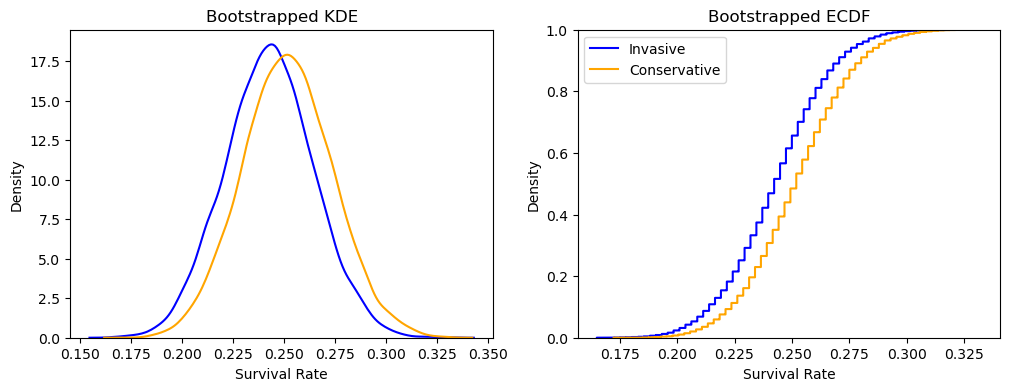

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

Based on the KDE, it looks like that the invasive group has a lower typical survival rate compared to the conservative group but that there is a lot of overlap in the density of survival rates between the two groups. The ECDF tells that at any individual proportion of our data the invasive group has a lower survival rate compared to the conservative group. These together say that the invasive group is leading to lower survivial rates compared to the conservative group but that this relationship is not very strong.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

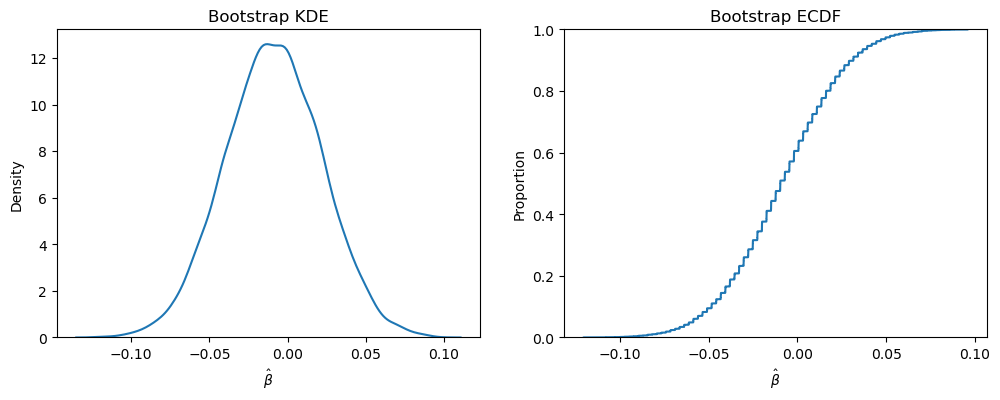

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


The Bootstrap KDE of the ATE is roughly a bell shape and contains values between around -0.12 and 0.12. This range of values is also shown in the Bootstrap ECDF.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05860951  0.04181386]
95% CI: [-0.06887887  0.0520501 ]
99% CI: [-0.08945094  0.07014424]


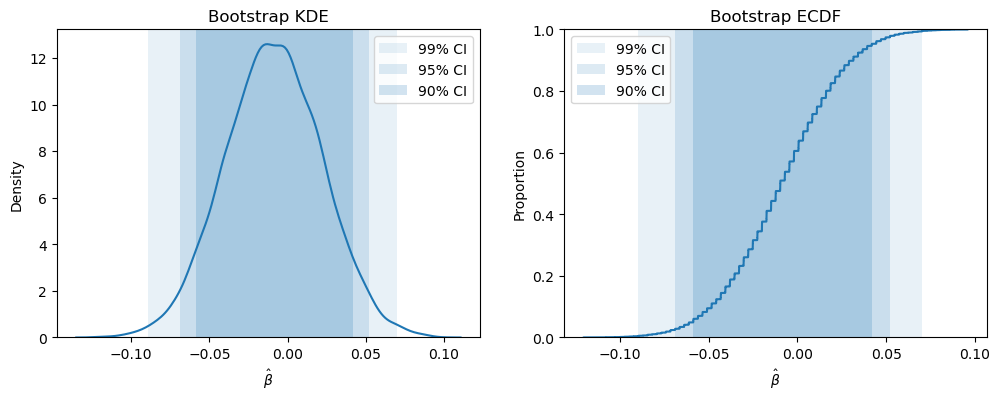

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

Yes, zero is in all of these confidence intervals. This means that we would fail to reject the null hypothesis that the effect size is zero based on each of the 90%, 95%, and 99% confidence intervals for the ATE. In order to reject the null hypothesis that the effect size is zero, it would need to be the case that zero is not in the confidence interval. 

**6.** What have we learned about inserting balloons into hearts?

We have learned that inserting balloons into hearts has no statistically signfigiant effect on survival rates and therefore should not be used during surgery.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [9]:
df2 = pd.read_csv('./data/diabetes.csv')
df2.head()

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [ ]:
# cross tab
print(pd.crosstab( df2['treatment'], df2['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [56]:
# calculating average outcomes
avg_outcome_life = df2.loc[ df2['treatment'] == 'lifestyle', 'outcome'].mean()
avg_outcome_met = df2.loc[df2['treatment'] == 'met', 'outcome'].mean()
avg_outcome_rosi = df2.loc[ df2['treatment'] == 'rosi', 'outcome'].mean()

print(f'Average Outcome Lifestyle: {np.round(avg_outcome_life,3)} \nAverage Outcome Met: {np.round(avg_outcome_met,3)} \nAverage Outcome Rosi: {np.round(avg_outcome_rosi,3)}')

Average Outcome Lifestyle: 0.534 
Average Outcome Met: 0.483 
Average Outcome Rosi: 0.614


Above are the average outcomes of the three groups with rosi having the highest success rate at 53.4%, lifestyle having the next highest at 48.3%, and met having the lowest at 62.4%.

In [55]:
# replacing outcome column such that failure=0 and success=1
df2['outcome'] = df2['outcome'].replace({'success': 1, 'failure': 0})

#lifestyle vs met
ate_lm = avg_outcome_life - avg_outcome_met

#lifestyle vs rosi
ate_lr = avg_outcome_life - avg_outcome_rosi

#met vs rosi
ate_mr = avg_outcome_met-avg_outcome_rosi

print(f'Estimated ATE Lifestyle vs Met: {np.round(ate_lm, 3)} \nEstimated ATE Lifestyle vs Rosi: {np.round(ate_lr, 3)} \nEstimated ATE Met vs Rosi: {np.round(ate_mr, 3)}')

Estimated ATE Lifestyle vs Met: 0.051 
Estimated ATE Lifestyle vs Rosi: -0.08 
Estimated ATE Met vs Rosi: -0.131


In [ ]:
## Bootstrapping:
R = 10_000

df_a = df2.loc[ df2['treatment'] == 'lifestyle',:]
df_b = df2.loc[ df2['treatment'] == 'met',:]
df_c = df2.loc[ df2['treatment'] == 'rosi',:]

outcome_a = []
outcome_b = []
outcome_c = []

ate_lm = [] # Store computed effects
ate_lr = []
ate_mr = []

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['outcome'].mean() # Mean outcome for lifestyle
    obt = df_bt['outcome'].mean() # Mean outcome for met
    oct = df_ct['outcome'].mean() # Mean outcome for rosi 

    ## Compute ATE:
    ate_tlm = oat - obt # Compute ATE for lifestyle vs met
    ate_tlr = oat - oct # Compute ATE for lifestyle vs rosi
    ate_tmr = obt - oct # Compute ATE for met vs rosi
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct) # Save new value
    ate_lm.append(ate_tlm) # Save new value
    ate_lr.append(ate_tlr) # Save new value
    ate_mr.append(ate_tmr) # Save new value

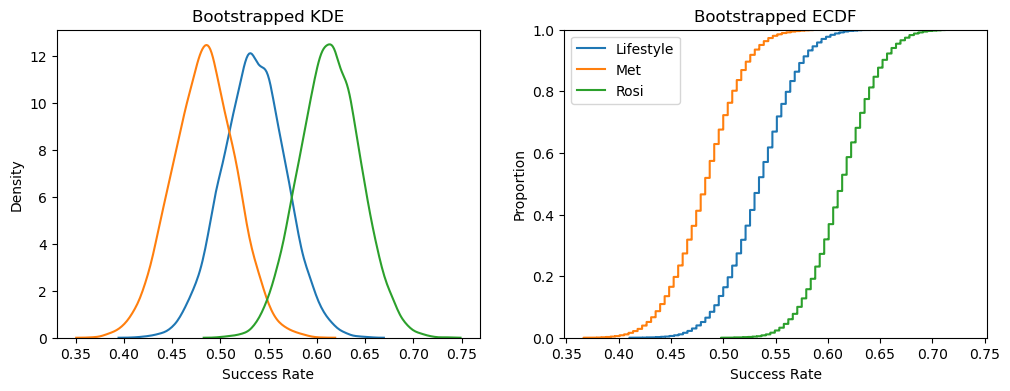

In [46]:
#plots of bootstrap KDE and ECDF - outcomes
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Lifestyle', ax=ax[0])
sns.kdeplot(outcome_b, label='Met', ax=ax[0])
sns.kdeplot(outcome_c, label='Rosi', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Lifestyle', ax=ax[1])
sns.ecdfplot(outcome_b, label='Met', ax=ax[1])
sns.ecdfplot(outcome_c, label='Rosi', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

In the above KDE chart I noticed that there is a large amount of overlap in density between the three groups but that met has the highest density at the lowest success rate while rosi has the highest density at the highest success rate and lifestyle is in-beetween the other two. The ECDF chart shows that for every individual proportion of data, met has a lower success rate compared to lifestyle and rosi and rosi has a higher success rate compared to lifestyle and met.

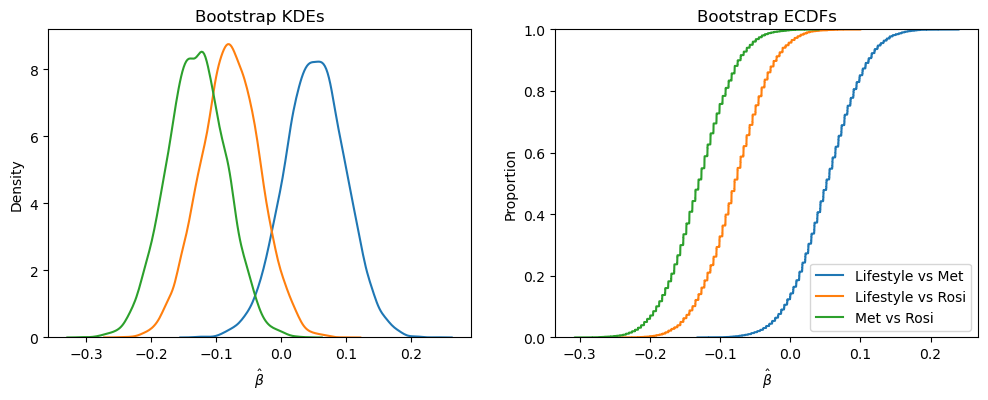

In [48]:
#plots of bootstrap KDE and ECDF - ATE
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_lm, ax=ax[0], label='Lifestyle vs Met')
sns.kdeplot(ate_lr, ax=ax[0], label='Lifestyle vs Rosi')
sns.kdeplot(ate_mr, ax=ax[0], label='Met vs Rosi')
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDEs")

## ECDF
sns.ecdfplot(ate_lm, ax=ax[1], label='Lifestyle vs Met')
sns.ecdfplot(ate_lr, ax=ax[1], label='Lifestyle vs Rosi')
sns.ecdfplot(ate_mr, ax=ax[1], label='Met vs Rosi')
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDFs")

plt.legend()
plt.show()

In [49]:
#confidence intervals lifestyle vs met
ci90 = np.quantile(ate_lm, [.05, .95])
ci95 = np.quantile(ate_lm, [.025, .975])
ci99 = np.quantile(ate_lm, [.005, .995])

print(f"90% CI lifestyle vs met: {ci90}")
print(f"95% CI lifestyle vs met: {ci95}")
print(f"99% CI lifestyle vs met: {ci99}")

90% CI lifestyle vs met: [-0.02578839  0.12857353]
95% CI lifestyle vs met: [-0.03912651  0.14161509]
99% CI lifestyle vs met: [-0.07312868  0.17138244]


In [50]:
#confidence intervals lifestyle vs rosi
ci90 = np.quantile(ate_lr, [.05, .95])
ci95 = np.quantile(ate_lr, [.025, .975])
ci99 = np.quantile(ate_lr, [.005, .995])

print(f"90% CI lifestyle vs rosi: {ci90}")
print(f"95% CI lifestyle vs rosi: {ci95}")
print(f"99% CI lifestyle vs rosi: {ci99}")

90% CI lifestyle vs rosi: [-0.15645061 -0.00258611]
95% CI lifestyle vs rosi: [-0.16950956  0.01034491]
99% CI lifestyle vs rosi: [-0.19505897  0.03605893]


In [51]:
#confidence intervals met vs rosi
ci90 = np.quantile(ate_mr, [.05, .95])
ci95 = np.quantile(ate_mr, [.025, .975])
ci99 = np.quantile(ate_mr, [.005, .995])

print(f"90% CI met vs rosi: {ci90}")
print(f"95% CI met vs rosi: {ci95}")
print(f"99% CI met vs rosi: {ci99}")

90% CI met vs rosi: [-0.20819243 -0.05760693]
95% CI met vs rosi: [-0.22110543 -0.04079057]
99% CI met vs rosi: [-0.24716979 -0.01069243]


Based on the confidence interval for lifestyle vs met, I do not see any sttistically signfigant difference between the two interventions. For lifestyle vs rosi, I only see a statistically signifigant negative difference between the interventions at the 90% CI. A negative difference means that lifestyle has a lower average success rate compared to rosi. Based on the confidence interval for met and rosi, I see a statistically signifigant negative difference between the two interventions for every CI. A negative difference here means that met had a lower success rate compared to rosi. Based on these results it seems that rosi may be the best intervention as it leads to statitically signfigantly higher success rates compared to met at every level of confidence and leads to statitically signfigantly higher success rates compared to lifestyle at the 90% CI.  